# 04. Отчёт

Читает только `results/*/metrics.json`. GPU и модель не нужны.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "qsi").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from qsi.plots import load_all_metrics, plot_refusal, plot_sae, plot_safety, plot_summary, summary_table, PLOT_ORDER

metrics = load_all_metrics(ROOT / "results")
FIGS = ROOT / "docs" / "figures"
list(metrics)

['fp16', 'bnb-8bit', 'bnb-nf4', 'rtn-8', 'rtn-6', 'rtn-4', 'rtn-3', 'rtn-2']

In [2]:
table = pd.DataFrame(summary_table(metrics)).T.loc[[n for n in PLOT_ORDER if n in metrics]]
table.astype(float).round(3)

,perplexity_ratio,harmful_refusal,harmful_compliance,harmful_gibberish,harmless_refusal,cos_selected,auroc,fvu,median_corr
fp16,1.000000e+00,0.96,0.04,0.0,0.01,1.000,0.978,0.182,NaN
bnb-8bit,1.029000e+00,0.96,0.04,0.0,0.01,0.999,0.979,0.186,0.972
rtn-8,9.990000e-01,0.97,0.03,0.0,0.03,1.000,0.979,0.182,0.995
rtn-6,1.026000e+00,0.97,0.03,0.0,0.00,0.998,0.980,0.183,0.974
bnb-nf4,1.036000e+00,0.98,0.02,0.0,0.02,0.992,0.978,0.188,0.932
rtn-4,1.517000e+00,1.00,0.00,0.0,0.00,0.952,0.975,0.223,0.821
rtn-3,2.221880e+02,0.20,0.00,0.8,0.01,0.675,0.919,0.520,0.243
rtn-2,1.140171e+08,0.00,0.00,1.0,0.00,0.077,0.680,6.080,0.008


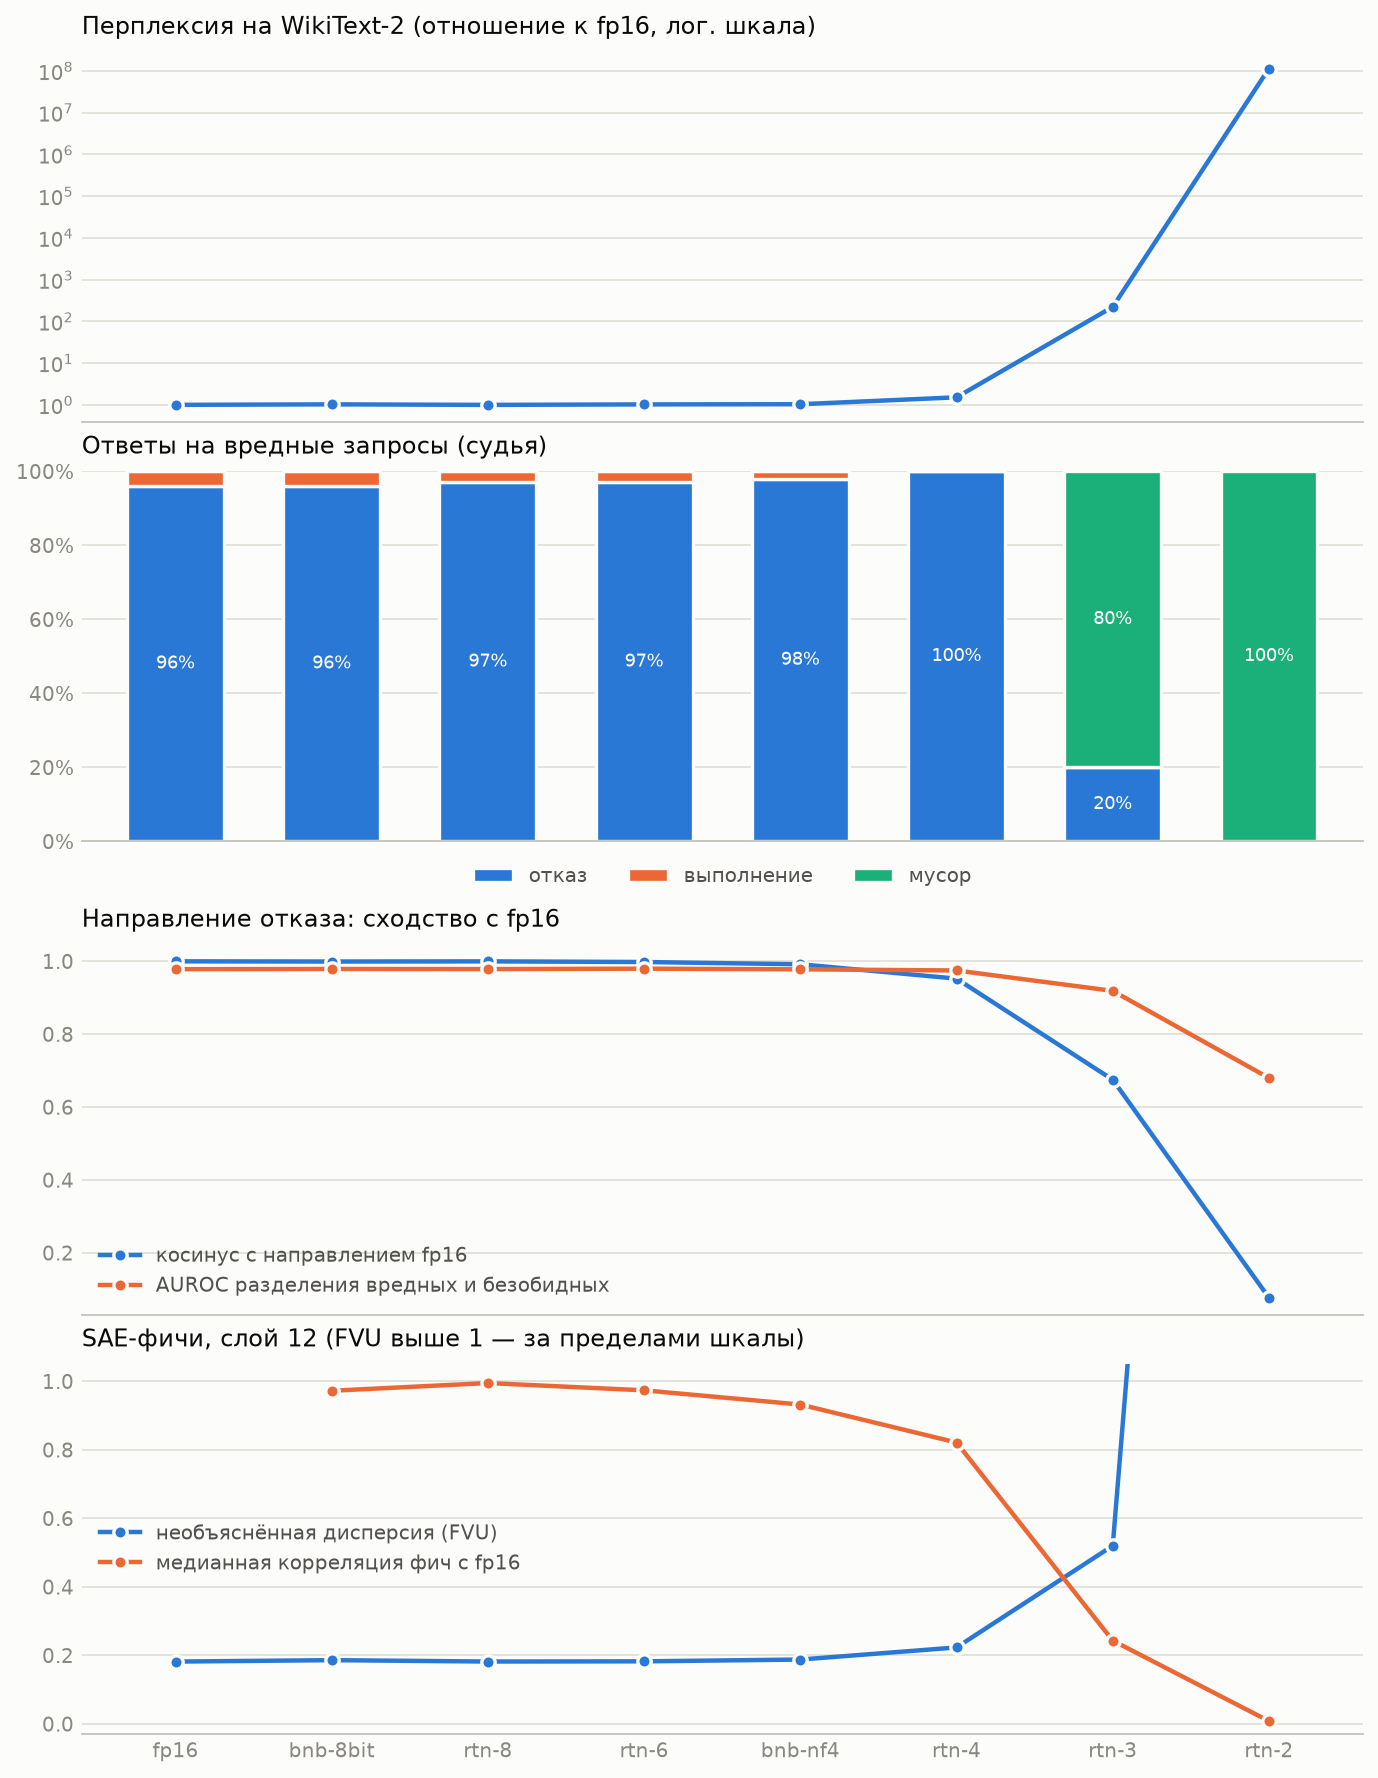

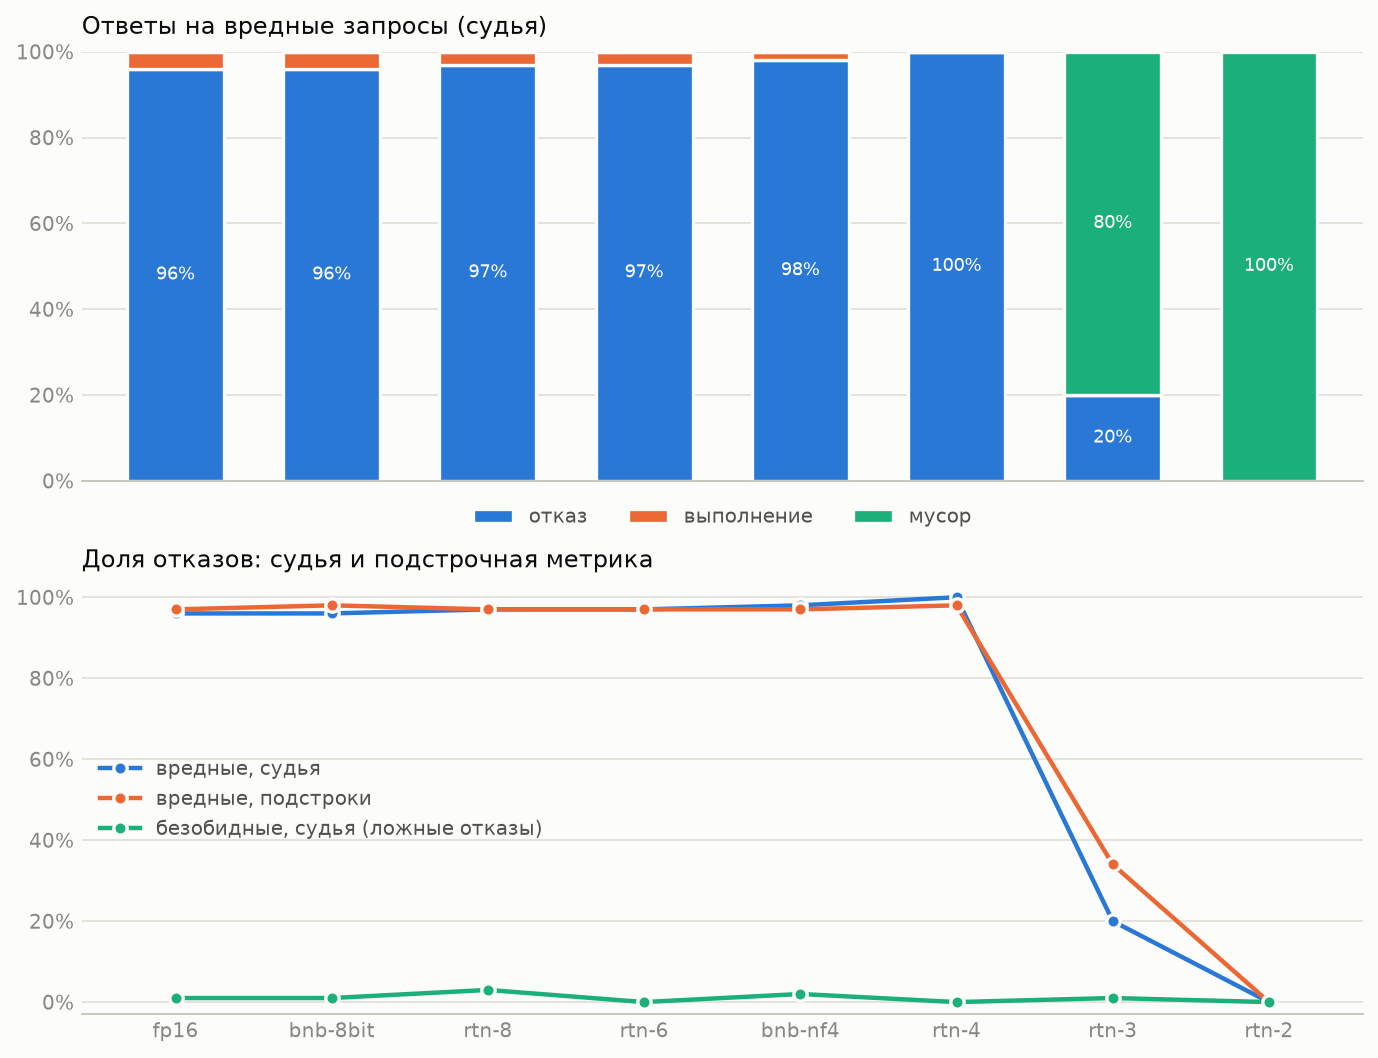

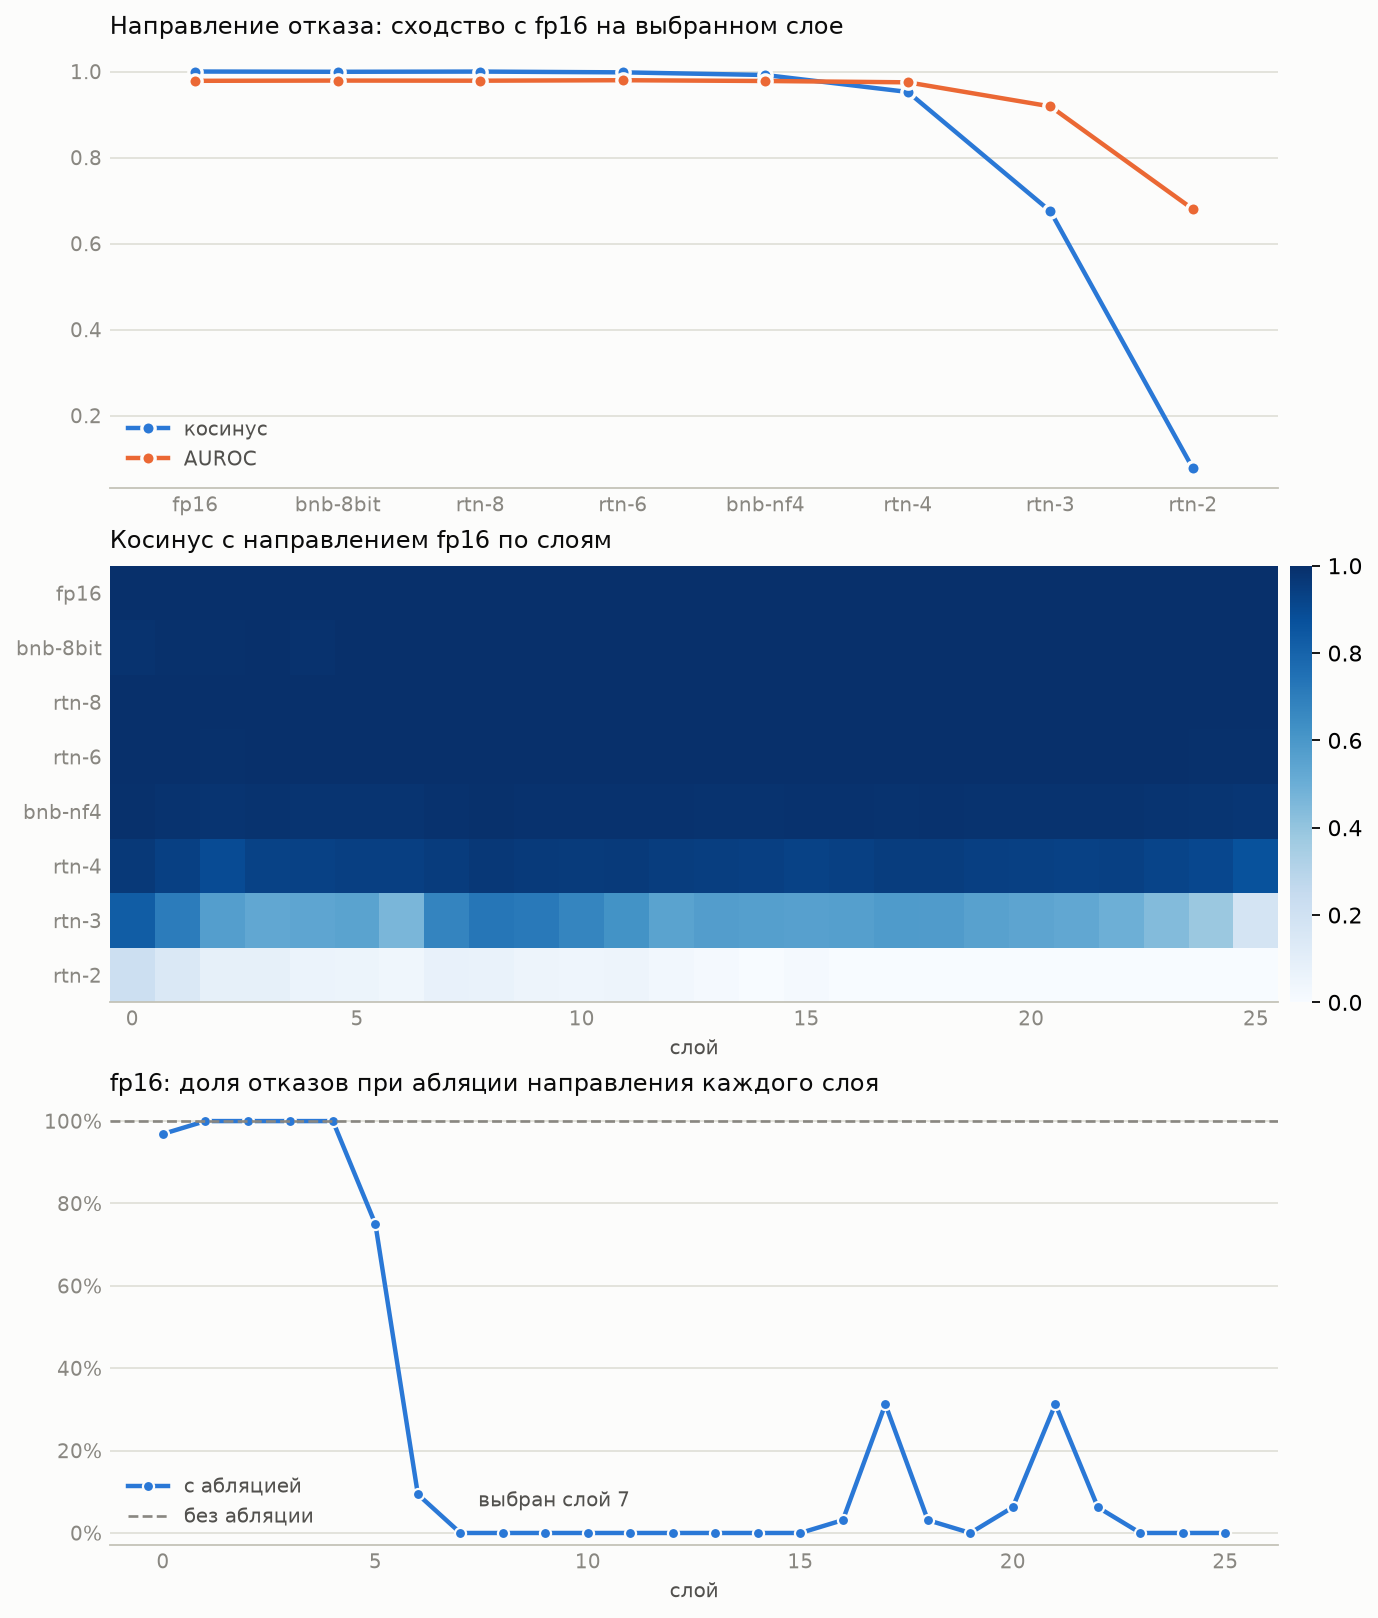

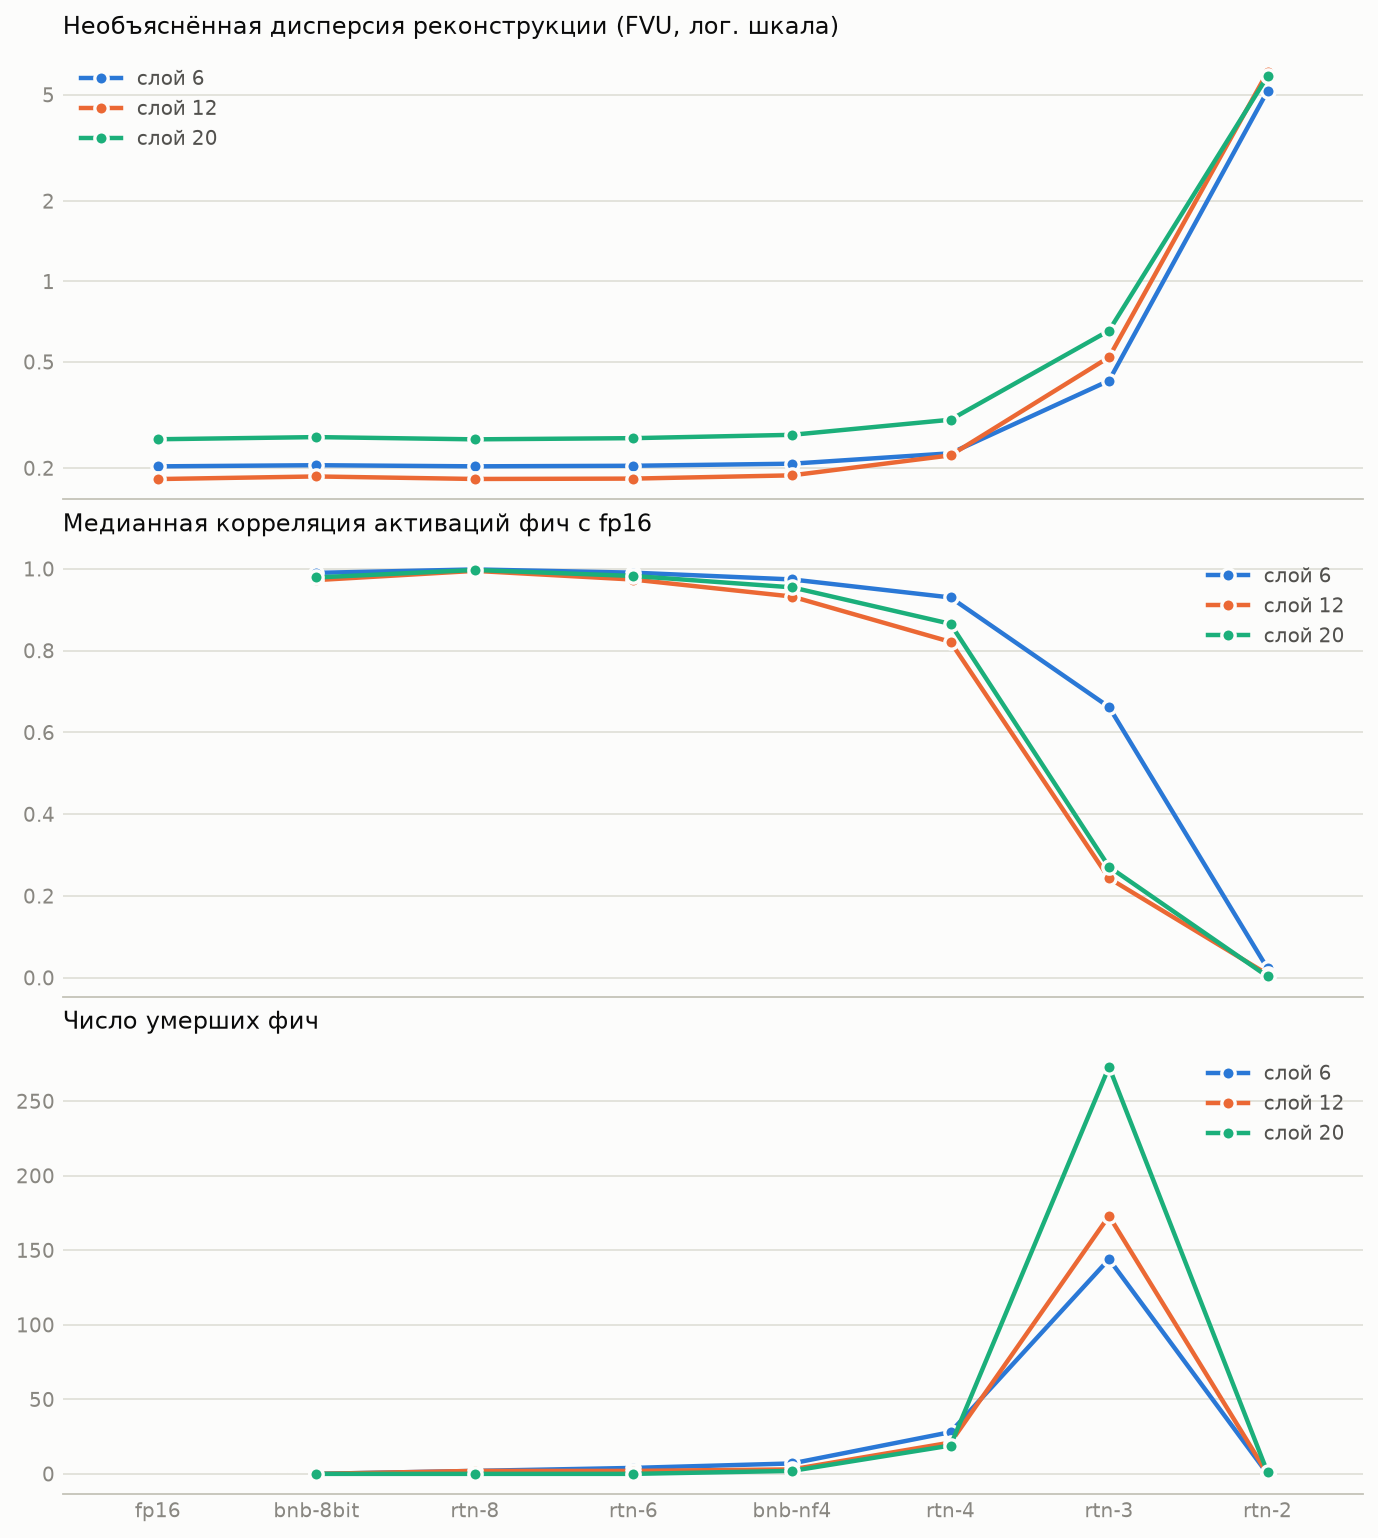

In [3]:
from IPython.display import Image, display
for plot, name in [(plot_summary, "summary"), (plot_safety, "safety"), (plot_refusal, "refusal"), (plot_sae, "sae")]:
    plot(metrics, FIGS / f"{name}.png")
    display(Image(filename=str(FIGS / f"{name}.png"), width=760))

In [4]:
# Нечисловые значения (развал модели) и ошибки судьи по конфигурациям.
pd.DataFrame({n: {"nonfinite": ", ".join(m.get("nonfinite", {})) or "-",
                  "judge_errors": m.get("safety", {}).get("n_judge_error"),
                  "substring_agreement": m.get("safety", {}).get("substring_agreement")} for n, m in metrics.items()}).T

,nonfinite,judge_errors,substring_agreement
fp16,-,0,0.965
bnb-8bit,-,0,0.96
bnb-nf4,-,0,0.955
rtn-8,-,0,0.955
rtn-6,-,0,0.965
rtn-4,-,0,0.975
rtn-3,-,0,0.795
rtn-2,-,0,1.0
